# Task 5: Netflix Trend Forecasting Model
Forecast how many titles Netflix will add in the coming months, using historical data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import itertools

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing

import warnings
warnings.filterwarnings("ignore")

## Load the Dataset

In [2]:
df = pd.read_csv("Dataset.csv")
print(df.shape)
df.head()

(8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


## Step 01: Prepare time-based features

In [3]:
# Convert the text column into real dates
df["date_added"] = pd.to_datetime(df["date_added"])

# Take out year and month
df["year_added"] = df["date_added"].dt.year
df["month_added"] = df["date_added"].dt.month

df[["date_added", "year_added", "month_added"]].head()

,date_added,year_added,month_added
0,2021-09-25,2021,9
1,2021-09-24,2021,9
2,2021-09-24,2021,9
3,2021-09-22,2021,9
4,2021-09-24,2021,9


### Make the monthly time series

In [4]:
# Count how many titles were added in each month
monthly = df.set_index("date_added").resample("MS").size()

# Keep 2016 to August 2021
# (before 2016 there is almost no data, and September 2021 is incomplete)
monthly = monthly["2016-01-01":"2021-08-01"]

print("Number of months:", len(monthly))
monthly.head()

Number of months: 68


date_added
2016-01-01    43
2016-02-01    15
2016-03-01    17
2016-04-01    22
2016-05-01    13
Freq: MS, dtype: int64

## Step 2: Analyze historical patterns (graph 1)

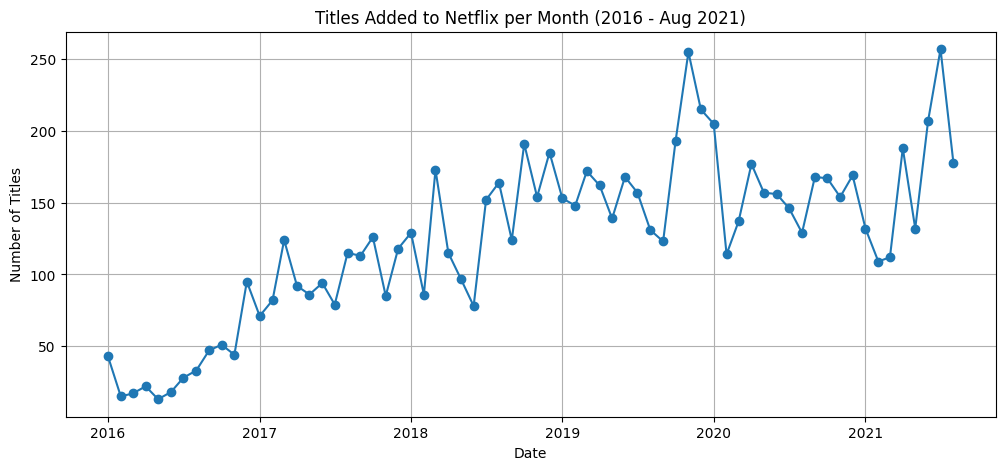

In [5]:
plt.figure(figsize=(12, 5))
plt.plot(monthly.index, monthly.values, marker="o")
plt.title("Titles Added to Netflix per Month (2016 - Aug 2021)")
plt.xlabel("Date")
plt.ylabel("Number of Titles")
plt.grid(True)
plt.show()

## Step 2: Analyze historical patterns (graph 2 & 3)

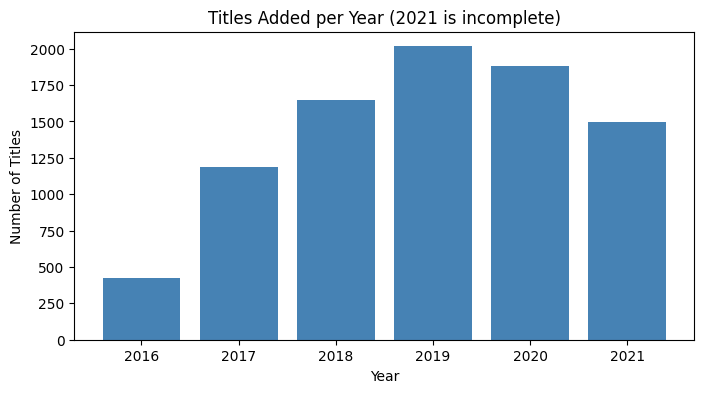

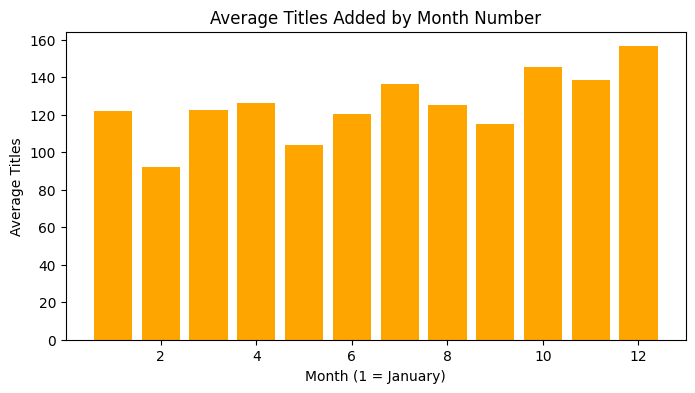

In [6]:
# Titles added per year
yearly = df[df["year_added"] >= 2016].groupby("year_added").size()

plt.figure(figsize=(8, 4))
plt.bar(yearly.index.astype(str), yearly.values, color="steelblue")
plt.title("Titles Added per Year (2021 is incomplete)")
plt.xlabel("Year")
plt.ylabel("Number of Titles")
plt.show()

# Which months are usually busier?
by_month = monthly.groupby(monthly.index.month).mean()

plt.figure(figsize=(8, 4))
plt.bar(by_month.index, by_month.values, color="orange")
plt.title("Average Titles Added by Month Number")
plt.xlabel("Month (1 = January)")
plt.ylabel("Average Titles")
plt.show()

### Split the data by time

In [7]:
# Last 12 months = test data, everything before = training data
test_size = 12
train = monthly.iloc[:-test_size]
test = monthly.iloc[-test_size:]

print("Training months:", len(train))
print("Test months:", len(test))

Training months: 56
Test months: 12


## Step 3: Build Model 1 (Linear Regression)

In [8]:
# Give every month a number: 0, 1, 2, 3 ...
X_all = np.arange(len(monthly)).reshape(-1, 1)
X_train = X_all[:-test_size]
X_test = X_all[-test_size:]

lr_model = LinearRegression()
lr_model.fit(X_train, train.values)

lr_pred = lr_model.predict(X_test)

## Step 3: Build Model 2 (ARIMA)

In [9]:
arima_model = ARIMA(train, order=(1, 1, 1))
arima_fit = arima_model.fit()

arima_pred = arima_fit.forecast(steps=test_size)

## Step 3: Build Model 3 (SARIMA)

In [10]:
# ARIMA that also learns a yearly (12 month) pattern
sarima_model = SARIMAX(train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12))
sarima_fit = sarima_model.fit(disp=False)

sarima_pred = sarima_fit.forecast(steps=test_size)

## Step 3: Build Model 4 (Holt-Winters)

In [11]:
# Exponential smoothing with trend and yearly pattern
hw_model = ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=12)
hw_fit = hw_model.fit()

hw_pred = hw_fit.forecast(test_size)

## Step 3: Build Model 5 (Tuned ARIMA)

In [12]:
# Try many ARIMA settings and keep the one with the smallest error
best_order = None
best_rmse = 10**9

for p, d, q in itertools.product(range(0, 4), range(0, 2), range(0, 4)):
    try:
        pred = ARIMA(train, order=(p, d, q)).fit().forecast(steps=test_size)
        rmse = np.sqrt(mean_squared_error(test, pred))
        if rmse < best_rmse:
            best_rmse = rmse
            best_order = (p, d, q)
    except Exception:
        continue

print("Best ARIMA settings:", best_order)

tuned_pred = ARIMA(train, order=best_order).fit().forecast(steps=test_size)

Best ARIMA settings: (3, 1, 3)


### Simple baseline for comparison

In [13]:
# Predict the average of the last 12 training months for every test month
baseline_pred = np.repeat(train.iloc[-12:].mean(), test_size)

## Step 4: Evaluate and compare the models

In [14]:
def get_scores(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    return mae, rmse

all_preds = {
    "Baseline (last 12 months average)": baseline_pred,
    "Linear Regression": lr_pred,
    "ARIMA (1,1,1)": arima_pred.values,
    f"ARIMA tuned {best_order}": tuned_pred.values,
    "SARIMA": sarima_pred.values,
    "Holt-Winters": hw_pred.values,
}

rows = []
for name, pred in all_preds.items():
    mae, rmse = get_scores(test, pred)
    rows.append([name, round(mae, 2), round(rmse, 2)])

results = pd.DataFrame(rows, columns=["Model", "MAE", "RMSE"])
results = results.sort_values("RMSE").reset_index(drop=True)
results

,Model,MAE,RMSE
0,Baseline (last 12 months average),30.08,40.09
1,"ARIMA tuned (3, 1, 3)",32.83,41.39
2,"ARIMA (1,1,1)",35.23,44.12
3,Holt-Winters,37.83,44.79
4,SARIMA,43.46,49.91
5,Linear Regression,54.37,61.84


### Compare the predictions on the test months (graph)

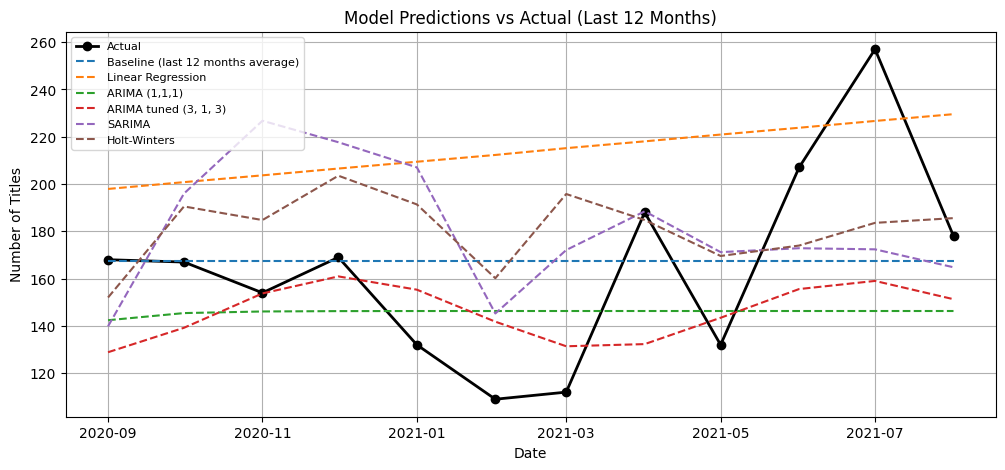

In [15]:
plt.figure(figsize=(12, 5))
plt.plot(test.index, test.values, label="Actual", color="black", marker="o", linewidth=2)
for name, pred in all_preds.items():
    plt.plot(test.index, pred, label=name, linestyle="--")
plt.title("Model Predictions vs Actual (Last 12 Months)")
plt.xlabel("Date")
plt.ylabel("Number of Titles")
plt.legend(fontsize=8)
plt.grid(True)
plt.show()

## Step 5: Generate future predictions

In [16]:
# Pick the model with the smallest RMSE (the baseline is only for comparison)
real_models = results[results["Model"] != "Baseline (last 12 months average)"]
best_model = real_models.iloc[0]["Model"]
print("Best model:", best_model)

# Next 12 months after August 2021
future_dates = pd.date_range(monthly.index[-1] + pd.offsets.MonthBegin(1),
                             periods=12, freq="MS")

# Train the best model again on ALL the data, then predict the future
if best_model == "Linear Regression":
    final_lr = LinearRegression()
    final_lr.fit(X_all, monthly.values)
    future_X = np.arange(len(monthly), len(monthly) + 12).reshape(-1, 1)
    future_values = final_lr.predict(future_X)
elif best_model == "ARIMA (1,1,1)":
    future_values = ARIMA(monthly, order=(1, 1, 1)).fit().forecast(steps=12).values
elif best_model.startswith("ARIMA tuned"):
    future_values = ARIMA(monthly, order=best_order).fit().forecast(steps=12).values
elif best_model == "SARIMA":
    final_sarima = SARIMAX(monthly, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12))
    future_values = final_sarima.fit(disp=False).forecast(steps=12).values
else:
    final_hw = ExponentialSmoothing(monthly, trend="add", seasonal="add", seasonal_periods=12)
    future_values = final_hw.fit().forecast(12).values

forecast = pd.Series(future_values, index=future_dates).round(0)
forecast

Best model: ARIMA tuned (3, 1, 3)


2021-09-01    168.0
2021-10-01    147.0
2021-11-01    154.0
2021-12-01    146.0
2022-01-01    152.0
2022-02-01    148.0
2022-03-01    152.0
2022-04-01    150.0
2022-05-01    153.0
2022-06-01    152.0
2022-07-01    154.0
2022-08-01    153.0
Freq: MS, dtype: float64

### Forecast graph

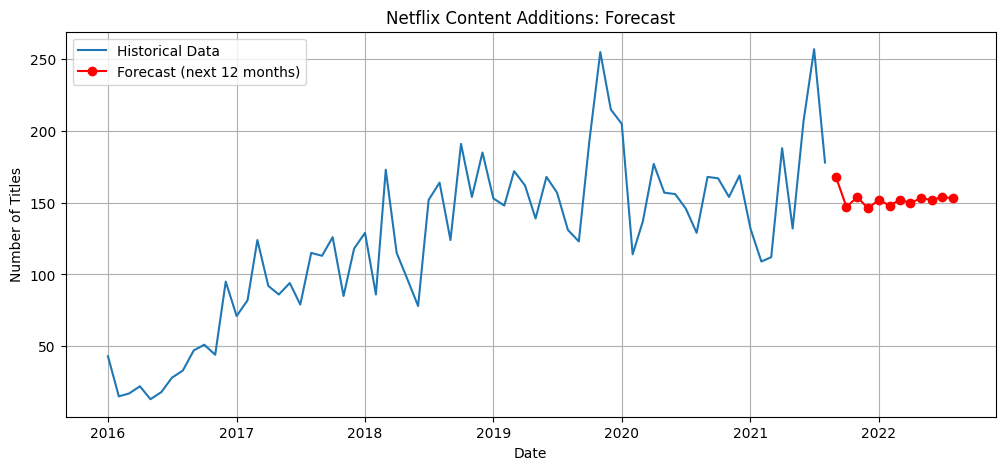

In [17]:
plt.figure(figsize=(12, 5))
plt.plot(monthly.index, monthly.values, label="Historical Data")
plt.plot(forecast.index, forecast.values, label="Forecast (next 12 months)",
         color="red", marker="o")
plt.title("Netflix Content Additions: Forecast")
plt.xlabel("Date")
plt.ylabel("Number of Titles")
plt.legend()
plt.grid(True)
plt.show()

# Conclusion

## What I saw in the data
I looked at how many titles Netflix added each month from 2016 to August 2021. The number grew a lot in the early years. It went from **426 titles in 2016** to **2,016 titles in 2019**. After 2019 it stayed high but dropped a little, to **1,879 in 2020**. The 2021 number looks lower only because the data stops in September, so that year is incomplete. The last three months of the year (October to December) were usually the busiest, and February was the slowest.

## Model results
I tested five models and one simple baseline on the last 12 months of data.

| Model | MAE | RMSE |
|---|---|---|
| Baseline (last 12 months average) | 30.08 | 40.09 |
| ARIMA tuned (3,1,3) | 32.83 | 41.39 |
| ARIMA (1,1,1) | 35.23 | 44.12 |
| Holt-Winters | 37.83 | 44.79 |
| SARIMA | 43.46 | 49.91 |
| Linear Regression | 54.37 | 61.84 |

A lower error means the predictions were closer to the real numbers. **The tuned ARIMA (3,1,3) was the best model** I built. Linear Regression was the weakest because it only draws a straight rising line, so it could not follow the changes after 2019. SARIMA and Holt-Winters did not beat ARIMA, most likely because 56 training months are too few to learn a yearly pattern well.

The simple baseline was almost as good as the best model, and its error was even a little smaller. This shows that the monthly numbers are hard to predict, and a complicated model gives only a small gain here.

## Forecast
I used the tuned ARIMA to predict the next 12 months (September 2021 to August 2022). It predicts about **150 new titles per month**. This is close to the recent level, so it suggests Netflix will keep adding content at a similar speed.

## Limitations
- The data has only about 5 years of monthly values (68 months), which is small for forecasting.
- The forecast is almost a flat line, so it does not show the month-to-month ups and downs.
- The ARIMA settings were chosen by looking at the same 12 test months, so its score is a little better than it would be on new data.
- The model only uses past counts. It does not know about real events like new Netflix plans or changes in the market.

## Future improvement
More data, or extra information such as genre and country, could give a better forecast.